In [3]:
from pycox.models import DeepHitSingle
from pycox.evaluation import EvalSurv
import torchtuples as tt

from tqdm import tqdm
import pandas as pd
import numpy as np
import torch

np.random.seed(42)
torch.manual_seed(42)

In [1]:
import pandas as pd
from pathlib import Path
feature_label_path = Path("/data/results/zj2398/femr/mimic/phenotype/results/ami/mamba_ntp_2e-4_730/features_with_label")
train_path = pd.read_parquet(feature_label_path/"train.parquet")
test_path = pd.read_parquet(feature_label_path/"test.parquet")
print(len(train_path),len(test_path))

124734 14527


In [12]:
# compare two dfs
from pathlib import Path
import pandas as pd

def find_overlapping_and_unique_rows(df1, df2, columns):
    """
    Find overlapping and unique rows between two DataFrames based on specified columns.
    """
    
    # Find overlapping rows (inner join)
    overlapping = df1.merge(df2[columns], on=columns, how='inner')
    
    # Find unique rows in df1 (left only)
    df1_with_indicator = df1.merge(df2[columns], on=columns, how='left', indicator=True)
    unique_df1 = df1_with_indicator[df1_with_indicator['_merge'] == 'left_only'].drop('_merge', axis=1)
    
    # Find unique rows in df2 (right only)
    df2_with_indicator = df2.merge(df1[columns], on=columns, how='left', indicator=True)
    unique_df2 = df2_with_indicator[df2_with_indicator['_merge'] == 'left_only'].drop('_merge', axis=1)
    
    return overlapping, unique_df1, unique_df2

# for task in ["ami","stroke","masld"]:
#     motor_dir = Path("/shared/share_mala/zj2398/mimic/task/phenotype_task/motor/labels/")
#     mtpp_dir = Path("/shared/share_mala/zj2398/mimic/task/phenotype_task/transformer_mtpp/labels/")
#     motor_label = pd.read_parquet(motor_dir/f"{task}.parquet")
#     mtpp_label = pd.read_parquet(mtpp_dir/f"{task}.parquet")
#     print(motor_label)
#     print(mtpp_label)
#     # task_dir_tte = pd.read_parquet(base_dir/"tte"/task/f"{task}.parquet")
#     overlapping,unique1,unique2 = find_overlapping_and_unique_rows(motor_label,mtpp_label,["subject_id","prediction_time","boolean_value","tte_label","time_to_event_days"])
#     print(len(overlapping))
#     print(len(unique1))
#     print(len(unique2))

for task in ["AMI","Ischemic_Stroke","MASLD","Celiac"]:
    first_event_dir = Path(f"/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/task_labels/phenotype_tte/binary/{task}")
    multiple_event_dir = Path(f"/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/task_labels/phenotype_tte/tte/{task}")
    
    parquet_first_files = sorted(first_event_dir.glob("*.parquet"))
    first_dfs = [pd.read_parquet(p) for p in parquet_first_files]
    first_event_combined = pd.concat(first_dfs, ignore_index=True)

    parquet_multiple_files = sorted(multiple_event_dir.glob("*.parquet"))
    multiple_dfs = [pd.read_parquet(p) for p in parquet_multiple_files]
    multiple_event_combined = pd.concat(multiple_dfs, ignore_index=True)
    # print(first_event_combined)
    # print(multiple_event_combined)
    print(len(multiple_event_combined[multiple_event_combined["time_to_event"]==0]))
    print(len(multiple_event_combined[multiple_event_combined["time_to_event"]<0]))

    overlapping,unique1,unique2 = find_overlapping_and_unique_rows(first_event_combined,multiple_event_combined,["subject_id","prediction_time","boolean_value"])
    print(len(overlapping))
    print(len(unique1))
    print(len(unique2))

    # for split in ["train","test"]:
    #     motor_split = pd.read_parquet(motor_dir/f"{split}.parquet")
    #     mtpp_split = pd.read_parquet(mtpp_dir/f"{split}.parquet")
        # print(motor_split)
        # print(mtpp_split)
        # task_dir_tte = pd.read_parquet(base_dir/"tte"/task/f"{task}.parquet")
        # overlapping,unique1,unique2 = find_overlapping_and_unique_rows(motor_split,mtpp_split,["subject_id","prediction_time","boolean_value","tte_label","time_to_event"])
        # print(len(overlapping))
        # print(len(unique1))
        # print(len(unique2))

0
0
146740
3260
0


0
0
147992
2008
0
0
0
148589
1411
0
0
0
148485
1515
0


In [1]:
from pathlib import Path
import pandas as pd

in_dir = Path("/shared/share_mala/zj2398/mimic/task/phenotype_task/cohort/tte/masld")
out_path = Path("/shared/share_mala/zj2398/mimic/task/phenotype_task/cohort/tte/masld/masld.parquet")

files = sorted(in_dir.glob("*.parquet"))
if not files:
    raise FileNotFoundError(f"No parquet files found in {in_dir}")

dfs = [pd.read_parquet(f) for f in files]
df = pd.concat(dfs, ignore_index=True)

df.to_parquet(out_path, index=False)
print("Wrote:", out_path, "rows:", len(df), "cols:", df.shape[1])


Wrote: /shared/share_mala/zj2398/mimic/task/phenotype_task/cohort/tte/masld/masld.parquet rows: 139944 cols: 6


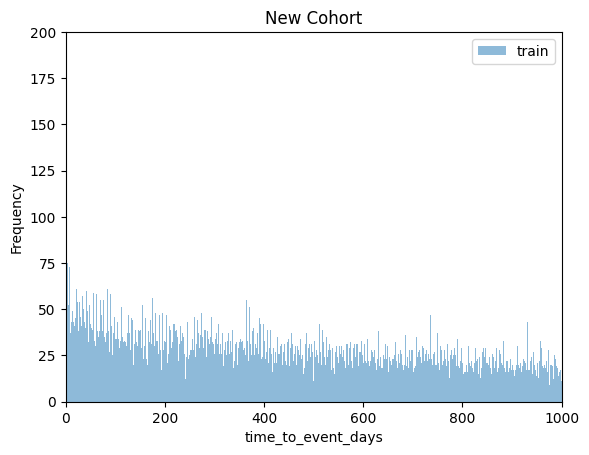

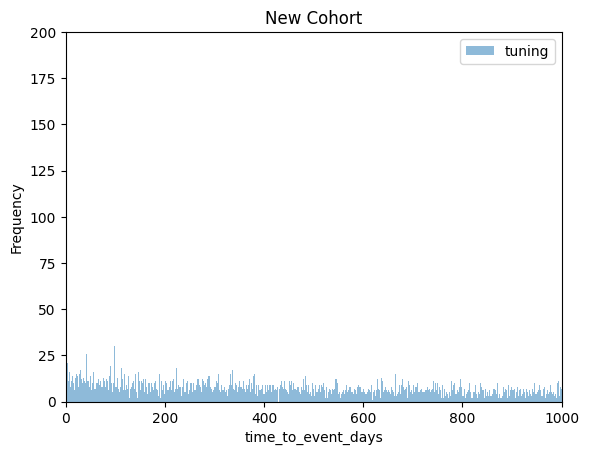

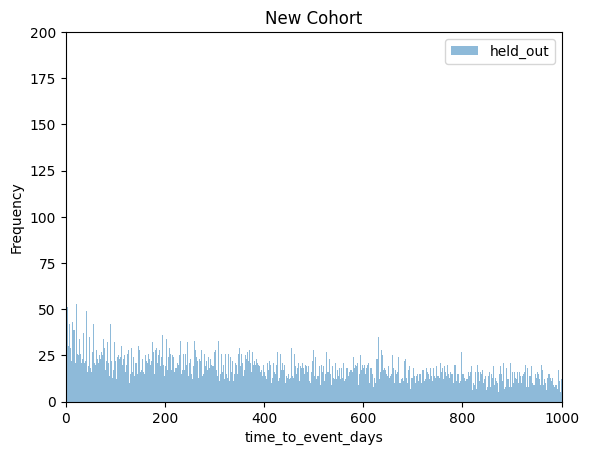

In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dir_path = Path("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/task_labels/tte_task_labels/Celiac")
for split in ["train","tuning","held_out"]:
    cohort = pd.read_parquet(dir_path/f"tte_{split}.parquet")
    # print(split_pd)
    cohort["time_to_event_days"] = cohort["time_to_event_hours"]/24
    # label = sorted(cohort["time_to_event_hours"].to_list())
    # print(label[1000])
    # cohort = cohort[cohort["time_to_event_days"]<=365]
    bins = np.arange(0, 1001, 1)
    ax = cohort["time_to_event_days"].plot.hist(bins=bins, alpha=0.5, label=split)

    plt.xlim(0, 1000)  # zoom in on first 100 days
    plt.ylim(0, 200)
    plt.xlabel("time_to_event_days")
    plt.ylabel("Frequency")
    plt.title("New Cohort")
    plt.legend()
    plt.show()

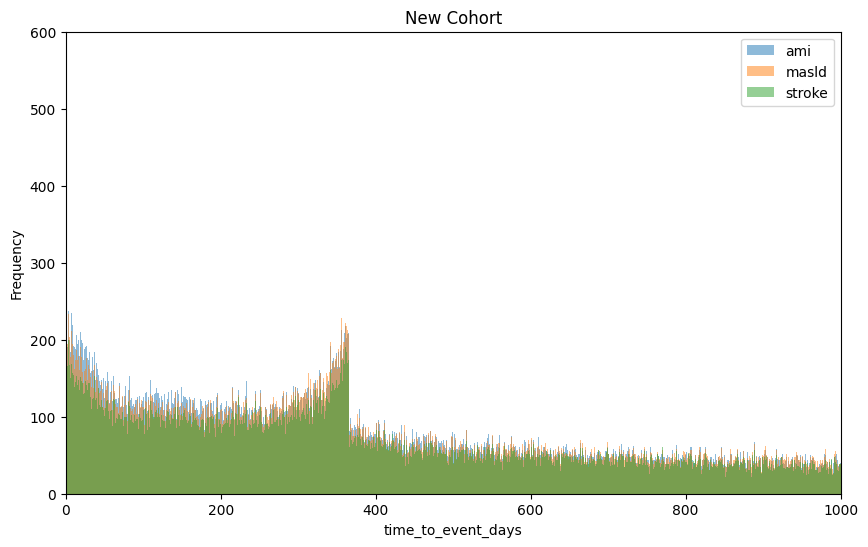

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# dir_path = Path("/shared/share_mala/zj2398/mimic/task/phenotype_task/cohort")
dir_path = Path("/shared/share_mala/zj2398/mimic/task/phenotype/")
plt.figure(figsize=(10, 6))
for task in ["ami","masld","stroke"]:
    cohort_path = dir_path/task/f"{task}.parquet"
    cohort = pd.read_parquet(cohort_path)
    # print(cohort)
    # cohort = cohort[cohort["tte_label"] == False]
    label = sorted(cohort["time_to_event_days"].to_list())
    # print(label[1000])
    # cohort = cohort[cohort["time_to_event_days"]<=365]
    bins = np.arange(0, 1001, 1)
    ax = cohort["time_to_event_days"].plot.hist(bins=bins, alpha=0.5, label=task)
    # cohort = cohort[cohort["time_to_event_days"]<=330]
    cohort["time_to_event_days"].plot.hist(bins=bins, alpha=0.5, label=task,ax=ax)
    # break

plt.xlim(0, 1000)  # zoom in on first 100 days
plt.ylim(0, 600)
plt.xlabel("time_to_event_days")
plt.ylabel("Frequency")
plt.title("New Cohort")
plt.legend()
plt.show()

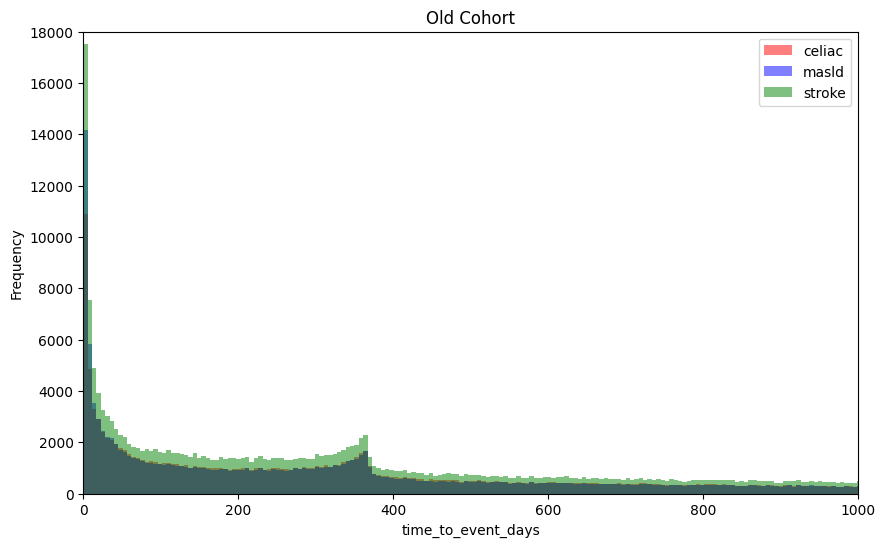

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

dir_path = Path("/shared/share_mala/zj2398/mimic/task/old_phenotype/motor/labels")
plt.figure(figsize=(10, 6))
diseases = ["celiac", "masld", "stroke"]
colors = ["red","blue","green"]
for idx in range(0,3):
    task = diseases[idx]
    cohort_path = dir_path/f"{task}.parquet"
    cohort = pd.read_parquet(cohort_path)
    cohort["time_to_event_days"].plot.hist(bins=1000, alpha=0.5, label=task,color=colors[idx])

plt.xlim(0, 1000)  # zoom in on first 100 days
plt.ylim(0, 18000)
plt.xlabel("time_to_event_days")
plt.ylabel("Frequency")
plt.title("Old Cohort")
plt.legend()
plt.show()

AMI
Ischemic_Stroke


MASLD
Celiac


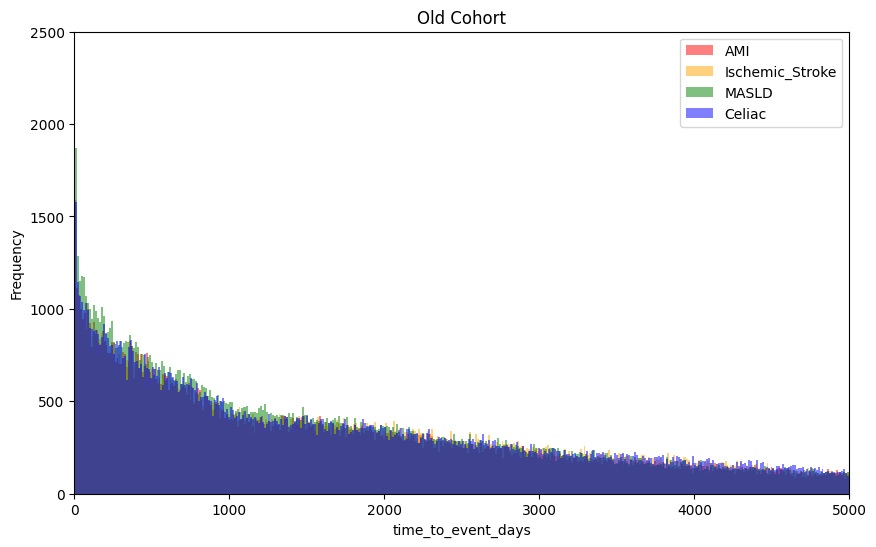

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

dir_path = Path("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/task_labels/phenotype_tte")
plt.figure(figsize=(10, 6))
for cohort_dir in dir_path.iterdir():
    if cohort_dir.is_dir(): 
        colors = {"AMI":"red", "Celiac":"blue", "MASLD":"green","Ischemic_Stroke":"orange"}
        dfs = []
        print(cohort_dir.name)
        for pq_path in sorted(cohort_dir.glob("*.parquet")):
            df = pd.read_parquet(pq_path)
            dfs.append(df)
        cohort = pd.concat(dfs,ignore_index=True)
        cohort["time_to_event"].plot.hist(bins=1000, alpha=0.5, label=cohort_dir.name,color=colors[cohort_dir.name])
        # print("finihsed")

plt.xlim(0, 5000)  # zoom in on first 100 days
plt.ylim(0, 2500)
plt.xlabel("time_to_event_days")
plt.ylabel("Frequency")
plt.title("Old Cohort")
plt.legend()
plt.show()

AMI


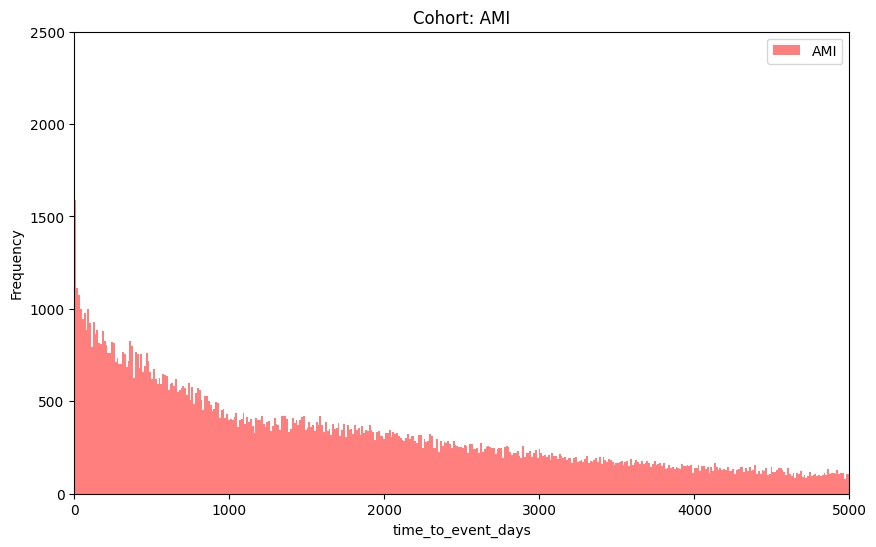

Ischemic_Stroke


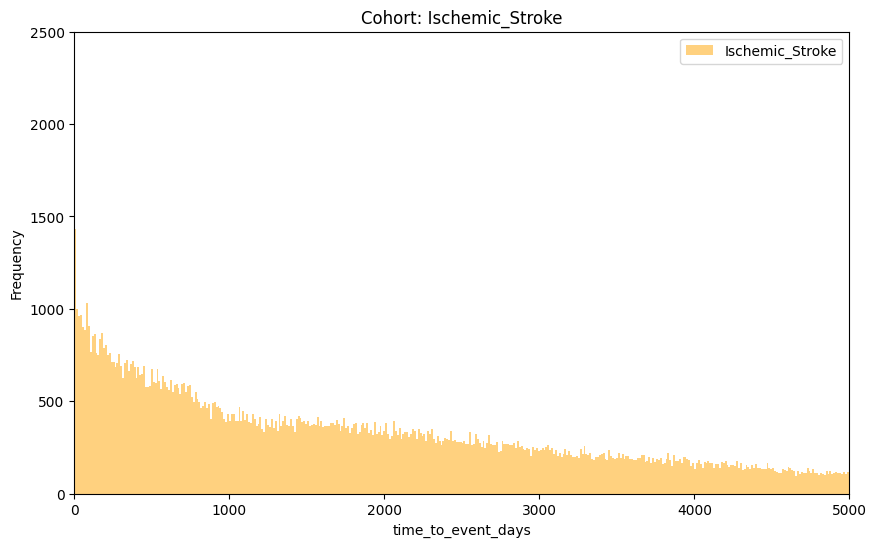

MASLD


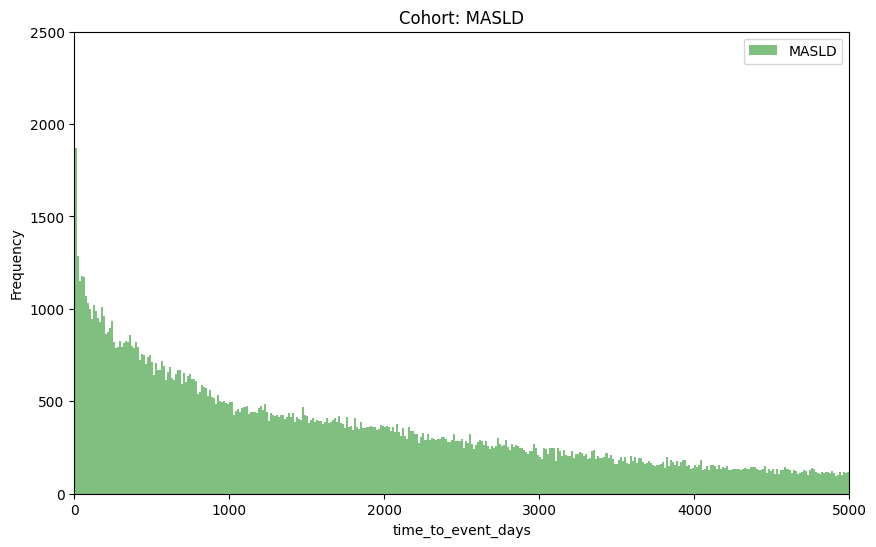

Celiac


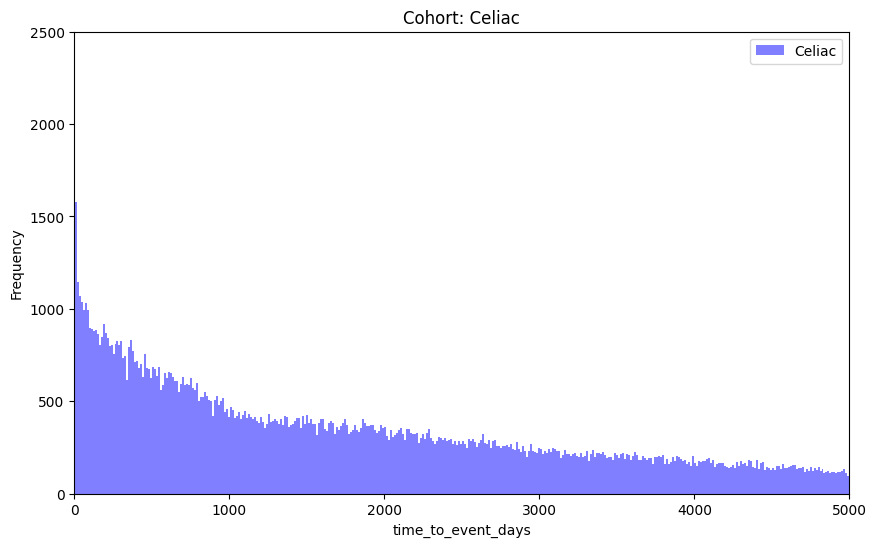

In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# dir_path = Path("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/task_labels/phenotype_tte")
# # plt.figure(figsize=(10, 6))
# for cohort_dir in dir_path.iterdir():
#     if cohort_dir.is_dir(): 
#         colors = {"AMI":"red", "Celiac":"blue", "MASLD":"green","Ischemic_Stroke":"orange"}
#         dfs = []
#         print(cohort_dir.name)
#         for pq_path in sorted(cohort_dir.glob("*.parquet")):
#             df = pd.read_parquet(pq_path)
#             dfs.append(df)
#         cohort = pd.concat(dfs,ignore_index=True)
#         cohort["time_to_event"].plot.hist(bins=1000, alpha=0.5, label=cohort_dir.name,color=colors[cohort_dir.name])
#         # print("finihsed")

#         plt.figure(figsize=(10, 6))
#         plt.xlim(0, 5000)  # zoom in on first 100 days
#         plt.ylim(0, 2500)
#         plt.xlabel("time_to_event_days")
#         plt.ylabel("Frequency")
#         plt.title("Old Cohort")
#         plt.legend()
#         plt.show()

# from pathlib import Path
# import pandas as pd
# import matplotlib.pyplot as plt

dir_path = Path("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/task_labels/phenotype_tte")

colors = {"AMI": "red", "Celiac": "blue", "MASLD": "green", "Ischemic_Stroke": "orange"}

for cohort_dir in dir_path.iterdir():
    if cohort_dir.is_dir():
        dfs = []
        print(cohort_dir.name)
        for pq_path in sorted(cohort_dir.glob("*.parquet")):
            df = pd.read_parquet(pq_path)
            dfs.append(df)

        cohort = pd.concat(dfs, ignore_index=True)

        # new figure for each cohort
        plt.figure(figsize=(10, 6))
        cohort["time_to_event"].plot.hist(
            bins=1000,
            alpha=0.5,
            label=cohort_dir.name,
            color=colors.get(cohort_dir.name, "gray"),  # safe lookup
        )

        plt.xlim(0, 5000)
        plt.ylim(0, 2500)
        plt.xlabel("time_to_event_days")
        plt.ylabel("Frequency")
        plt.title(f"Cohort: {cohort_dir.name}")
        plt.legend()
        plt.show()


In [ ]:
# merge df

# fetch tte labels from phenotype task to processed task
from pathlib import Path
import pandas as pd
import pickle
import numpy as np
import femr
import femr.featurizers
import femr.splits

diseases = ["stroke","masld"]
# phenotype_dir = Path("/data/processed_datasets/processed_datasets/mimic/phenotype_task")
# file1 = pd.read_parquet('/data/processed_datasets/processed_datasets/mimic/phenotype_task/celiac/celiac_cohort.parquet')
phenotype_dir = Path("/user/zj2398/cache/mimic/mimic-3.1-meds/phenotype_task")
embedding_dir = Path("/user/zj2398/cache/motor_mimic_8k/results")
for disease in diseases:
    df1 = pd.read_parquet(phenotype_dir / disease / f"{disease}_cohort.parquet")
    # print(cohort_label.head())

    for split in ["train", "test"]:
        split_path = embedding_dir / disease/ f"motor/features_with_label/{split}.parquet"
        with open(split_path, 'rb') as f:
            df2 = pd.read_parquet(f)
        print(df2)


        # --- 0) (Optional) make copies so originals stay intact
        df1_ = df1.copy()
        df2_ = df2.copy()

        # --- 1) Ensure dtypes match exactly
        # prediction_time to datetime (naive)
        df1_["prediction_time"] = pd.to_datetime(df1_["prediction_time"], errors="raise", utc=False)
        df2_["prediction_time"] = pd.to_datetime(df2_["prediction_time"], errors="raise", utc=False)

        # boolean_value to proper bool
        # (handles cases where it's already bool or string "True"/"False")
        df1_["boolean_value"] = df1_["boolean_value"].astype(str).str.lower().map({"true": True, "false": False})
        df2_["boolean_value"] = df2_["boolean_value"].astype(str).str.lower().map({"true": True, "false": False})

        # subject_id to consistent integer (or string if you prefer)
        df1_["subject_id"] = pd.to_numeric(df1_["subject_id"], downcast="integer")
        df2_["subject_id"] = pd.to_numeric(df2_["subject_id"], downcast="integer")

        # --- 2) Check that the join key is unique on the right side (df1)
        key_cols = ["subject_id", "prediction_time", "boolean_value"]
        dupes = df1_.duplicated(subset=key_cols, keep=False)
        if dupes.any():
            # Show a few offending keys to help diagnose
            raise ValueError(
                "df1 has duplicate rows for the join key; expected 1 row per key.\n"
                f"Examples:\n{df1_.loc[dupes, key_cols].head(10)}"
            )

        # --- 3) Merge (df2 left-join to df1), enforcing m:1 cardinality
        merged = df2_.merge(
            df1_[key_cols + ["time_to_event_days"]],
            on=key_cols,
            how="left",
            validate="m:1"
        )

        # --- 4) Verify every df2 row matched something in df1
        num_unmatched = merged["time_to_event_days"].isna().sum()
        if num_unmatched:
            # Show a few missing keys to debug
            missing_keys = merged.loc[merged["time_to_event_days"].isna(), key_cols].drop_duplicates().head(10)
            raise ValueError(
                f"{num_unmatched} row(s) in df2 did not find a match in df1. "
                f"Examples of missing keys:\n{missing_keys}"
            )

        # --- 5) If you only want df2 + the added label:
        df2_with_label = merged  # same columns as df2, plus time_to_event_days
        # print(df2_with_label)
        df2_with_label.to_parquet(split_path)






